In [5]:
print('In the name of Allah')

In the name of Allah


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.datasets import load_wine

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

from sklearn.metrics import confusion_matrix, classification_report


In [31]:
df = load_wine(as_frame = True).frame

df.sample(5)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
137,12.53,5.51,2.64,25.0,96.0,1.79,0.60,0.63,1.10,5.00,0.82,1.69,515.0,2
143,13.62,4.95,2.35,20.0,92.0,2.00,0.80,0.47,1.02,4.40,0.91,2.05,550.0,2
128,12.37,1.63,2.30,24.5,88.0,2.22,2.45,0.40,1.90,2.12,0.89,2.78,342.0,1
31,13.58,1.66,2.36,19.1,106.0,2.86,3.19,0.22,1.95,6.90,1.09,2.88,1515.0,0
25,13.05,2.05,3.22,25.0,124.0,2.63,2.68,0.47,1.92,3.58,1.13,3.20,830.0,0


In [32]:
df.shape

(178, 14)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [34]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


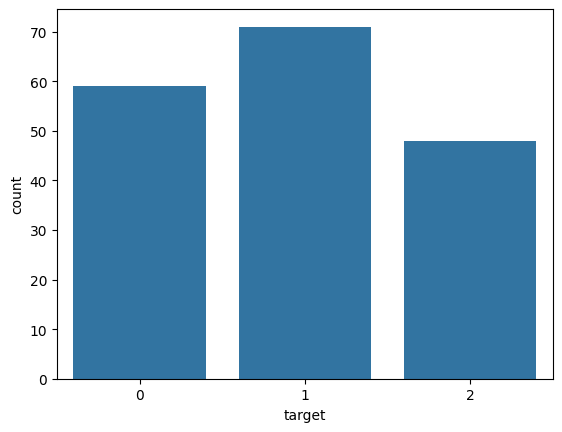

In [35]:
sns.countplot(data = df, x = 'target')

plt.show()

In [36]:
X = df.drop('target', axis = 1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42, stratify = y )

In [37]:
X_train

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
36,13.28,1.64,2.84,15.5,110.0,2.60,2.68,0.34,1.36,4.60,1.09,2.78,880.0
30,13.73,1.50,2.70,22.5,101.0,3.00,3.25,0.29,2.38,5.70,1.19,2.71,1285.0
26,13.39,1.77,2.62,16.1,93.0,2.85,2.94,0.34,1.45,4.80,0.92,3.22,1195.0
12,13.75,1.73,2.41,16.0,89.0,2.60,2.76,0.29,1.81,5.60,1.15,2.90,1320.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
142,13.52,3.17,2.72,23.5,97.0,1.55,0.52,0.50,0.55,4.35,0.89,2.06,520.0
87,11.65,1.67,2.62,26.0,88.0,1.92,1.61,0.40,1.34,2.60,1.36,3.21,562.0
34,13.51,1.80,2.65,19.0,110.0,2.35,2.53,0.29,1.54,4.20,1.10,2.87,1095.0
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0


In [38]:
y_train.nunique()

3

In [39]:
knn_model = Pipeline(
    steps = [
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors = 15, metric = 'minkowski', p = 2 ))
    ]
)

knn_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier(n_neighbors=15))])

In [40]:
y_pred = knn_model.predict(X_test)

y_pred

array([0, 2, 0, 1, 1, 0, 0, 1, 1, 2, 1, 2, 0, 2, 0, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 2, 1, 2, 0, 2, 1, 2, 2, 2])

In [41]:
accuracy = accuracy_score(y_test, y_pred)

print(accuracy)

1.0


In [42]:
conf_mat = confusion_matrix(y_test, y_pred)

conf_mat

array([[12,  0,  0],
       [ 0, 14,  0],
       [ 0,  0, 10]])

In [44]:
print( classification_report(y_test, y_pred) )

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [60]:
# p2

performance = []
acc = []

for k in range( 5, 30 ) :

  # if k % 2 != 0 and k % 3 != 0 :
  knn_model = Pipeline(
    steps = [
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors = k, metric = 'minkowski', p = 2 ))
    ]
    )

  knn_model.fit(X_train, y_train)

  y_pred = knn_model.predict(X_test)

  accuracy = round(accuracy_score(y_test, y_pred), 4)

  precision = round(precision_score(y_test, y_pred, average = 'weighted'), 4)
  recall = round(recall_score(y_test, y_pred, average = 'weighted'), 4)
  acc.append(accuracy)

  performance.append( (k, (accuracy, precision, recall)) )


In [64]:
print(performance)

[(5, (0.9722, 0.9747, 0.9722)), (6, (0.9722, 0.9741, 0.9722)), (7, (1.0, 1.0, 1.0)), (8, (1.0, 1.0, 1.0)), (9, (1.0, 1.0, 1.0)), (10, (1.0, 1.0, 1.0)), (11, (1.0, 1.0, 1.0)), (12, (1.0, 1.0, 1.0)), (13, (1.0, 1.0, 1.0)), (14, (0.9722, 0.9744, 0.9722)), (15, (1.0, 1.0, 1.0)), (16, (1.0, 1.0, 1.0)), (17, (1.0, 1.0, 1.0)), (18, (0.9722, 0.9744, 0.9722)), (19, (1.0, 1.0, 1.0)), (20, (1.0, 1.0, 1.0)), (21, (1.0, 1.0, 1.0)), (22, (1.0, 1.0, 1.0)), (23, (1.0, 1.0, 1.0)), (24, (1.0, 1.0, 1.0)), (25, (1.0, 1.0, 1.0)), (26, (1.0, 1.0, 1.0)), (27, (1.0, 1.0, 1.0)), (28, (0.9722, 0.9744, 0.9722)), (29, (0.9722, 0.9744, 0.9722))]


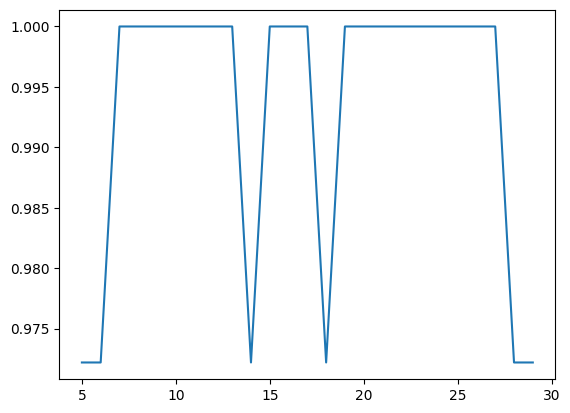

In [63]:
plt.plot(range(5, 30), acc)

plt.show()

In [65]:
# p1

performance = []
acc = []

for k in range( 5, 30 ) :

  # if k % 2 != 0 and k % 3 != 0 :
  knn_model = Pipeline(
    steps = [
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors = k, metric = 'minkowski', p = 1 ))
    ]
    )

  knn_model.fit(X_train, y_train)

  y_pred = knn_model.predict(X_test)

  accuracy = round(accuracy_score(y_test, y_pred), 4)

  precision = round(precision_score(y_test, y_pred, average = 'weighted'), 4)
  recall = round(recall_score(y_test, y_pred, average = 'weighted'), 4)
  acc.append(accuracy)

  performance.append( (k, (accuracy, precision, recall)) )


In [66]:
print(performance)

[(5, (1.0, 1.0, 1.0)), (6, (1.0, 1.0, 1.0)), (7, (1.0, 1.0, 1.0)), (8, (1.0, 1.0, 1.0)), (9, (1.0, 1.0, 1.0)), (10, (0.9722, 0.9744, 0.9722)), (11, (0.9722, 0.9744, 0.9722)), (12, (0.9722, 0.9744, 0.9722)), (13, (0.9722, 0.9744, 0.9722)), (14, (0.9722, 0.9744, 0.9722)), (15, (0.9722, 0.9744, 0.9722)), (16, (0.9722, 0.9744, 0.9722)), (17, (0.9722, 0.9744, 0.9722)), (18, (0.9722, 0.9744, 0.9722)), (19, (0.9722, 0.9744, 0.9722)), (20, (0.9722, 0.9744, 0.9722)), (21, (0.9722, 0.9744, 0.9722)), (22, (0.9722, 0.9744, 0.9722)), (23, (0.9722, 0.9744, 0.9722)), (24, (0.9722, 0.9744, 0.9722)), (25, (0.9722, 0.9744, 0.9722)), (26, (0.9444, 0.9524, 0.9444)), (27, (0.9444, 0.9524, 0.9444)), (28, (0.9444, 0.9524, 0.9444)), (29, (0.9444, 0.9524, 0.9444))]


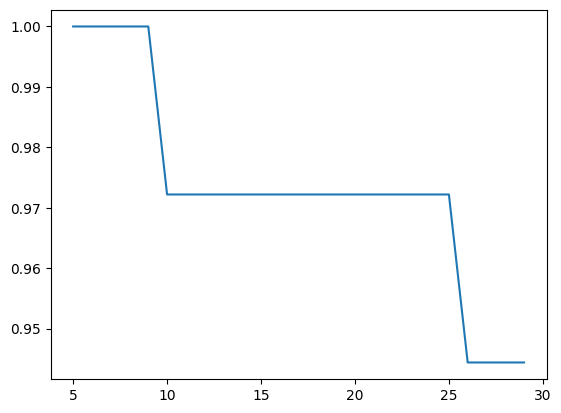

In [67]:
plt.plot(range(5, 30), acc)

plt.show()